<a href="https://colab.research.google.com/github/whiteblack1858/yolo8-custum-traking/blob/main/yolov8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# YOLOv8 커스텀 학습 + 객체 추적 과제
Colab에서 `런타임 > 런타임 유형 변경 > GPU(T4)`로 바꾼 뒤 위에서부터 차례로 실행한다.
`TODO`로 표시된 값만 본인 것으로 바꾸면 된다.

## 0. 설치 및 GPU 확인

In [ ]:
!pip -q install ultralytics roboflow
import ultralytics; ultralytics.checks()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


## 1. 데이터셋 가져오기
**방법 A (추천): Roboflow** — 프로젝트에서 `Versions > Export Dataset > Format: YOLOv8 > show download code`를 누르면 나오는 값을 아래에 넣는다.
**방법 B: 직접 zip 업로드** — `data.yaml`, `train/`, `valid/`, `test/`가 들어 있는 zip을 Drive에 올려두고 아래 B 셀을 쓴다.

In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key)                          # TODO
project = rf.workspace(workspace).project(project_name)  # TODO
dataset = project.version(1).download("yolov8")                 # TODO: 버전 번호
DATA_YAML = f"{dataset.location}/data.yaml"
print(DATA_YAML)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to machine-learning-1 in yolov8:: 100%|██████████| 645/645 [00:00<00:00, 7909.43it/s]

/content/machine-learning-1/data.yaml


In [ ]:
# 방법 B: Drive의 zip 사용 (방법 A를 썼다면 실행하지 않는다)
# from google.colab import drive; drive.mount('/content/drive')
# !unzip -q /content/drive/MyDrive/dataset.zip -d /content/dataset   # TODO: 경로
# DATA_YAML = "/content/dataset/data.yaml"

In [ ]:
# 데이터 구성 확인 (보고서에 그대로 쓸 수 있다)
import yaml, os, glob
cfg = yaml.safe_load(open(DATA_YAML)); root = os.path.dirname(DATA_YAML)
print("클래스:", cfg["names"])
for split in ["train", "valid", "test"]:
    n = len(glob.glob(f"{root}/{split}/images/*"))
    print(f"{split}: {n}장")

클래스: ['razor', 'toilet_paper', 'wallet']
train: 321장
valid: 0장
test: 0장


### 데이터 분할 보정
Roboflow에서 분할을 하지 않으면 `valid`/`test` 폴더 없이 전부 `train`에 들어간다. 아래 셀은 그런 경우 train의 일부를 valid(20%)·test(10%)로 옮긴다. Roboflow 증강 사본은 파일명의 `.rf.` 앞부분이 같으므로 같은 원본끼리 묶어서 옮기고, valid/test에는 원본당 한 장만 남겨 증강 사본이 평가에 섞이지 않게 한다. 이미 분할돼 있으면 아무것도 하지 않는다.

In [ ]:
import random, shutil
from collections import defaultdict
random.seed(42)
cnt = lambda s: len(glob.glob(f"{root}/{s}/images/*"))
missing = [s for s in ["valid", "test"] if cnt(s) == 0]
if missing:
    groups = defaultdict(list)
    for p in glob.glob(f"{root}/train/images/*"):
        groups[os.path.basename(p).split(".rf.")[0]].append(p)
    keys = sorted(groups); random.shuffle(keys)
    n_val, n_test = int(len(keys) * 0.2), int(len(keys) * 0.1)
    plan = {"valid": keys[:n_val], "test": keys[n_val:n_val + n_test]}
    for split in missing:
        os.makedirs(f"{root}/{split}/images", exist_ok=True); os.makedirs(f"{root}/{split}/labels", exist_ok=True)
        for k in plan[split]:
            for j, p in enumerate(groups[k]):
                stem = os.path.splitext(os.path.basename(p))[0]
                lb = f"{root}/train/labels/{stem}.txt"
                if j == 0:                                   # 원본당 한 장만 평가용으로 옮긴다
                    shutil.move(p, f"{root}/{split}/images/")
                    if os.path.exists(lb): shutil.move(lb, f"{root}/{split}/labels/")
                else:                                        # 나머지 증강 사본은 삭제
                    os.remove(p)
                    if os.path.exists(lb): os.remove(lb)
cfg = yaml.safe_load(open(DATA_YAML))
cfg.pop("path", None)
cfg["train"], cfg["val"], cfg["test"] = (f"{root}/{s}/images" for s in ["train", "valid", "test"])
yaml.safe_dump(cfg, open(DATA_YAML, "w"), allow_unicode=True)
for s in ["train", "valid", "test"]: print(f"{s}: {cnt(s)}장")

train: 228장
valid: 21장
test: 10장


## 2. 학습 (전이학습)
COCO로 사전학습된 `yolov8n.pt`를 불러와 출력 클래스만 3개로 바꿔 학습한다. 시간이 남으면 `yolov8s.pt`로 바꿔 비교해 보면 보고서 거리가 된다.

In [ ]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
results = model.train(
    data=DATA_YAML,
    epochs=50,        # 데이터가 적으면 50~100
    imgsz=640,
    batch=16,
    patience=20,      # 20 epoch 동안 개선이 없으면 조기 종료
    project="runs", name="hw", exist_ok=True,
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/machine-learning-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=hw, nbs=64, nms=None, opset=None, optimize=False, op

## 3. 성능 확인 (보고서용)

/content/runs/detect/runs/hw
results.png


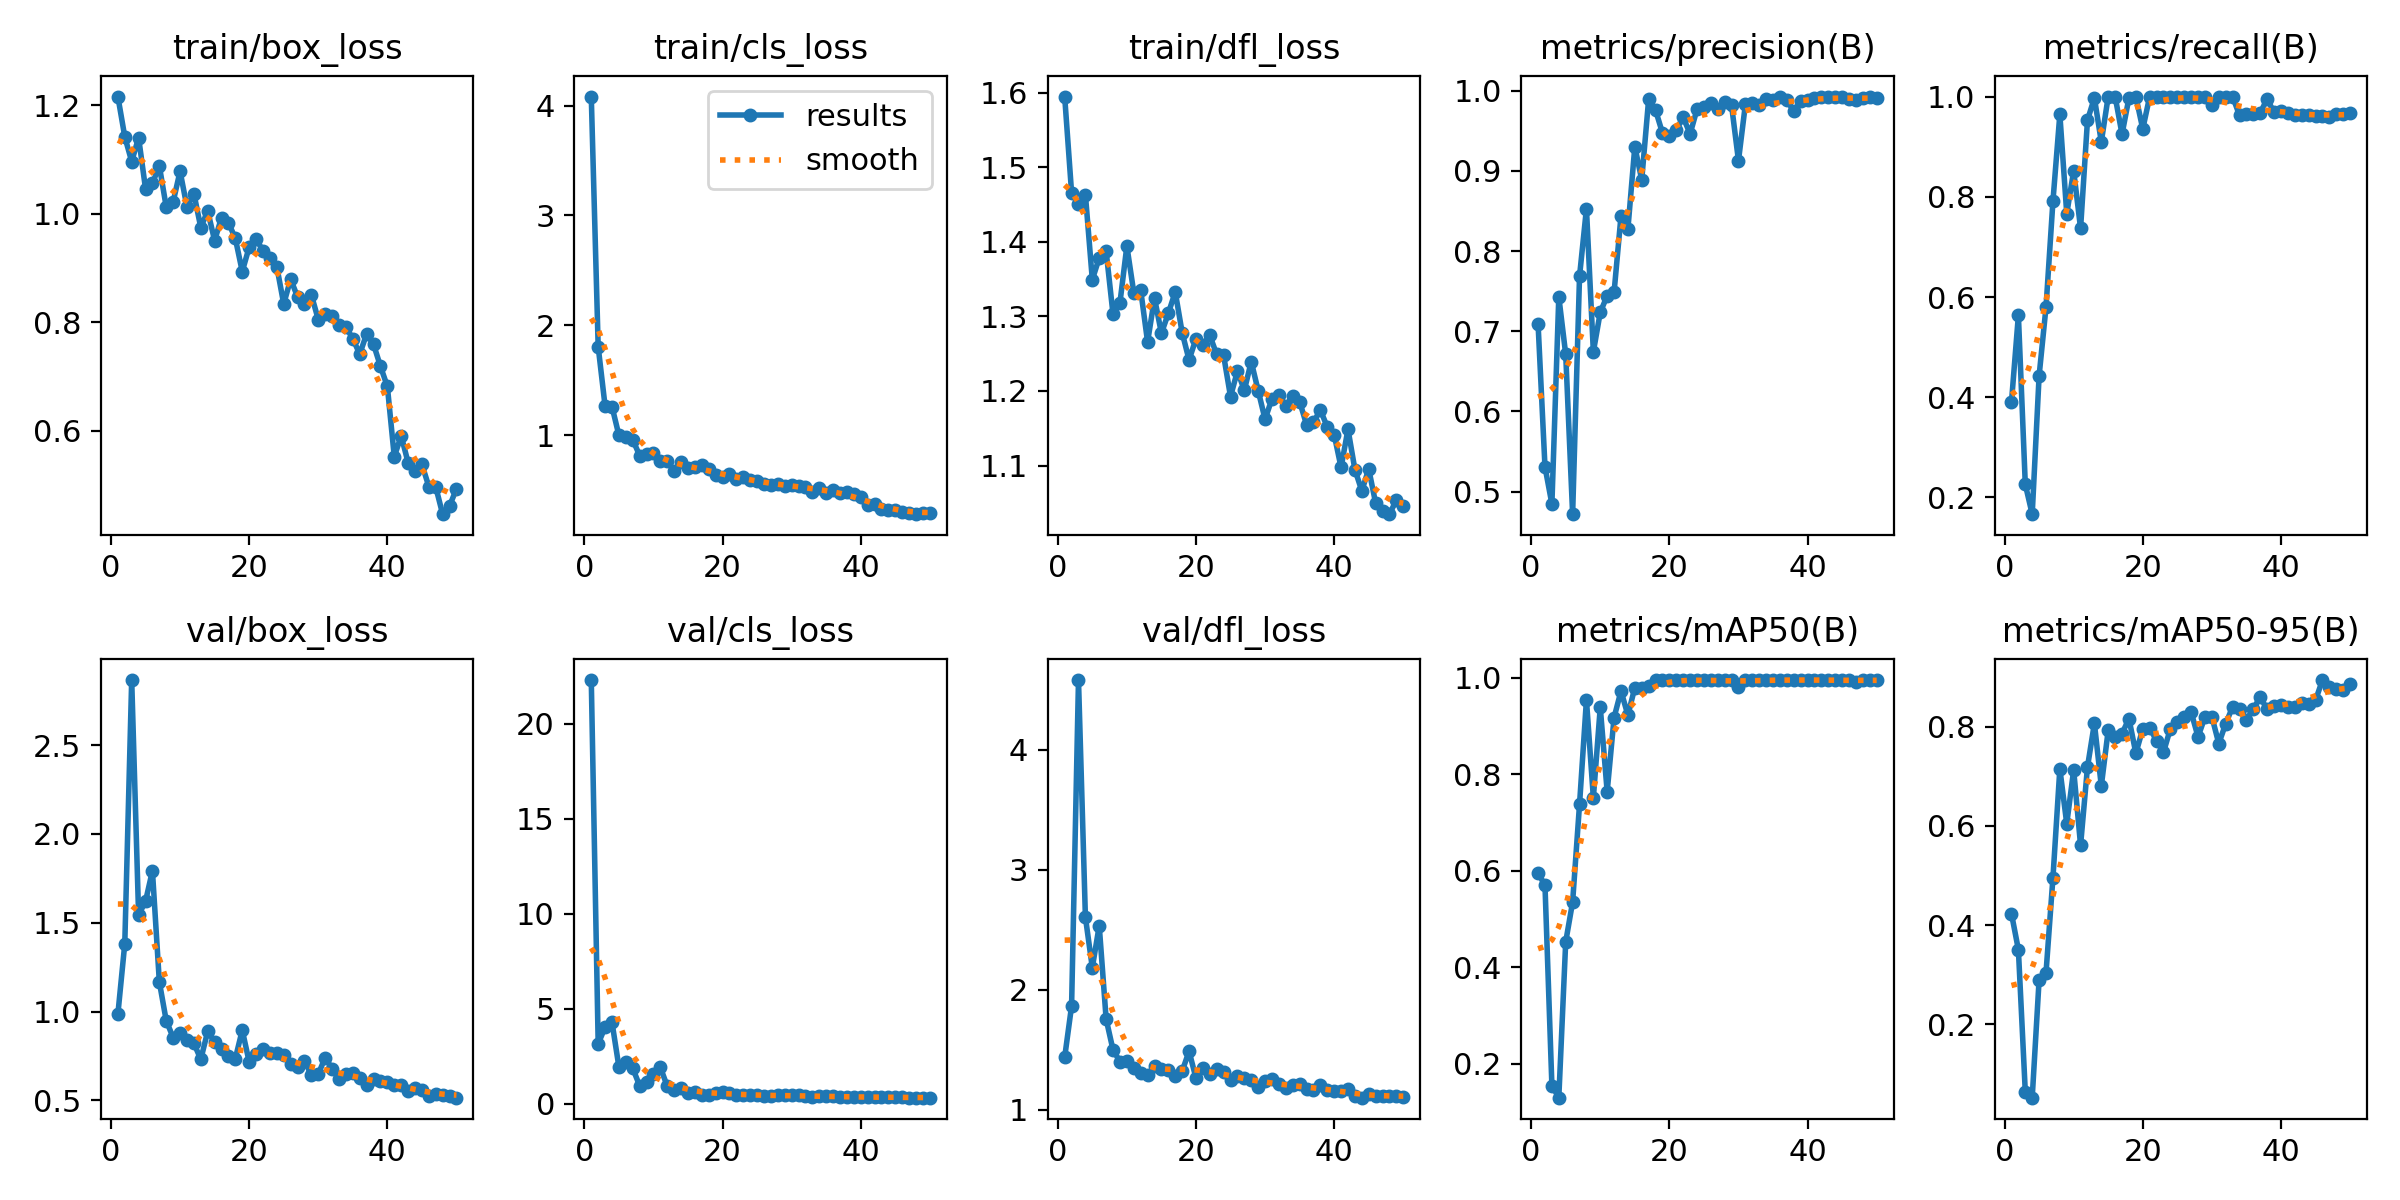

confusion_matrix.png


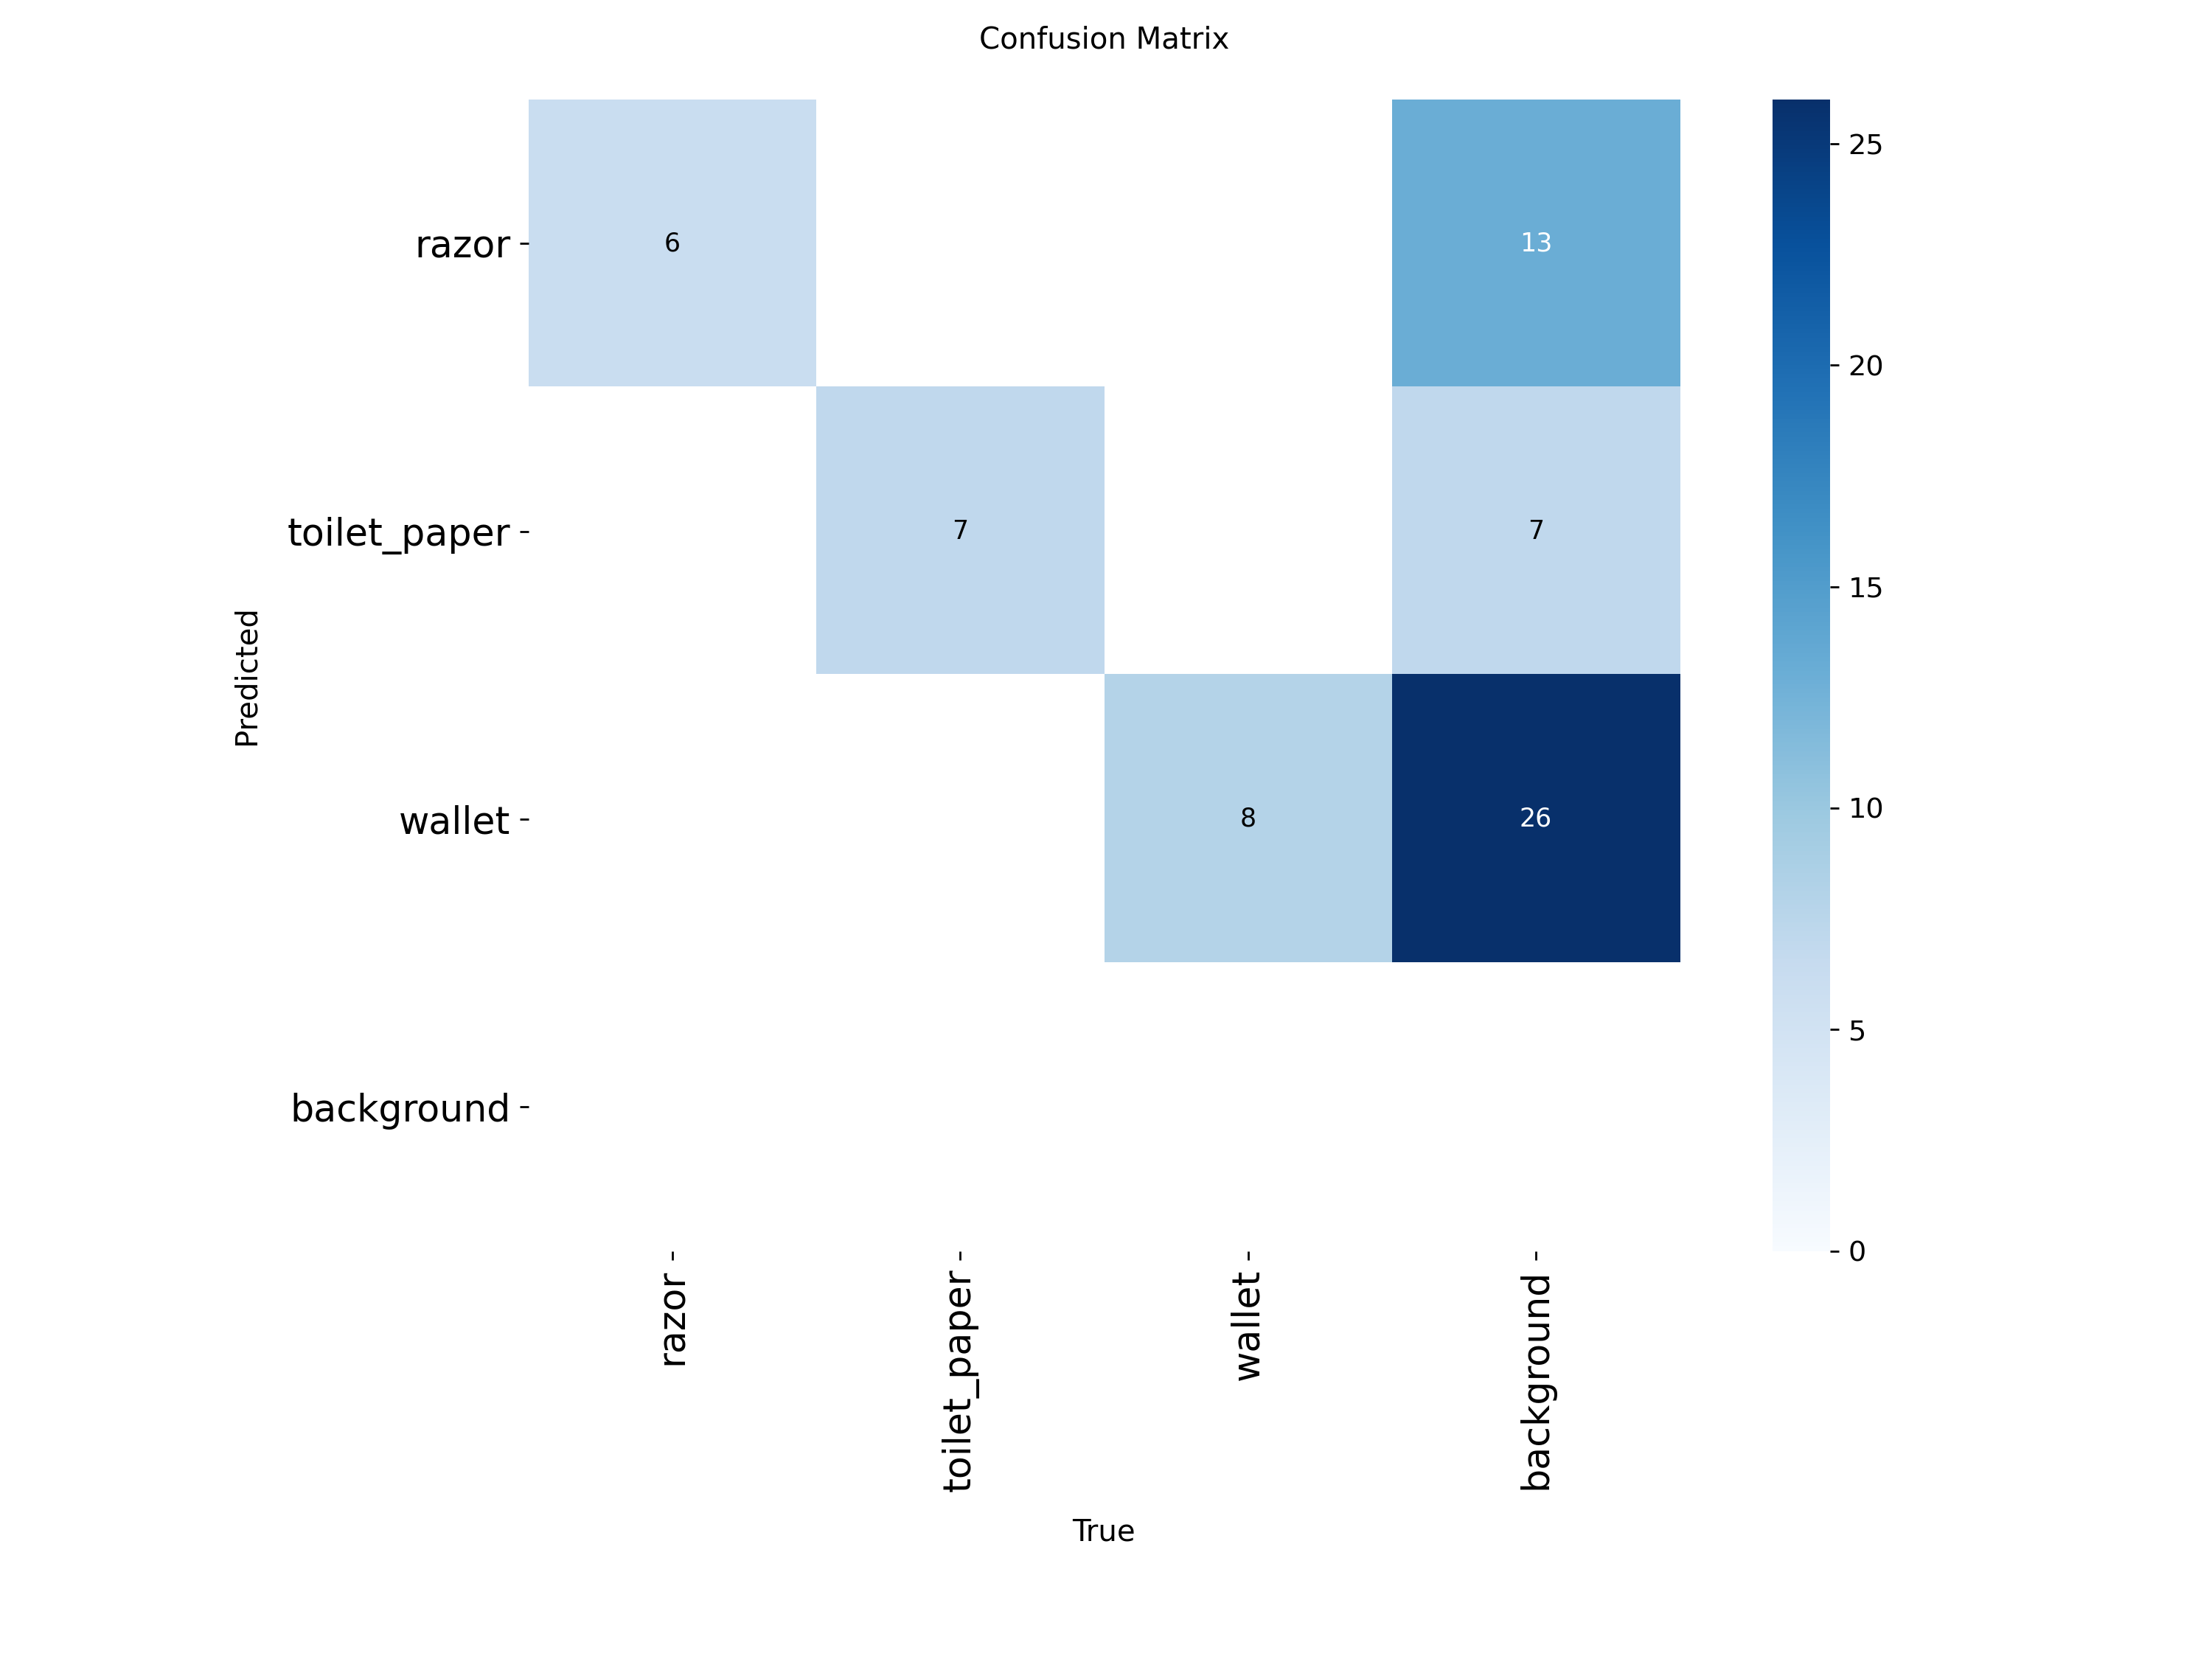

val_batch0_pred.jpg


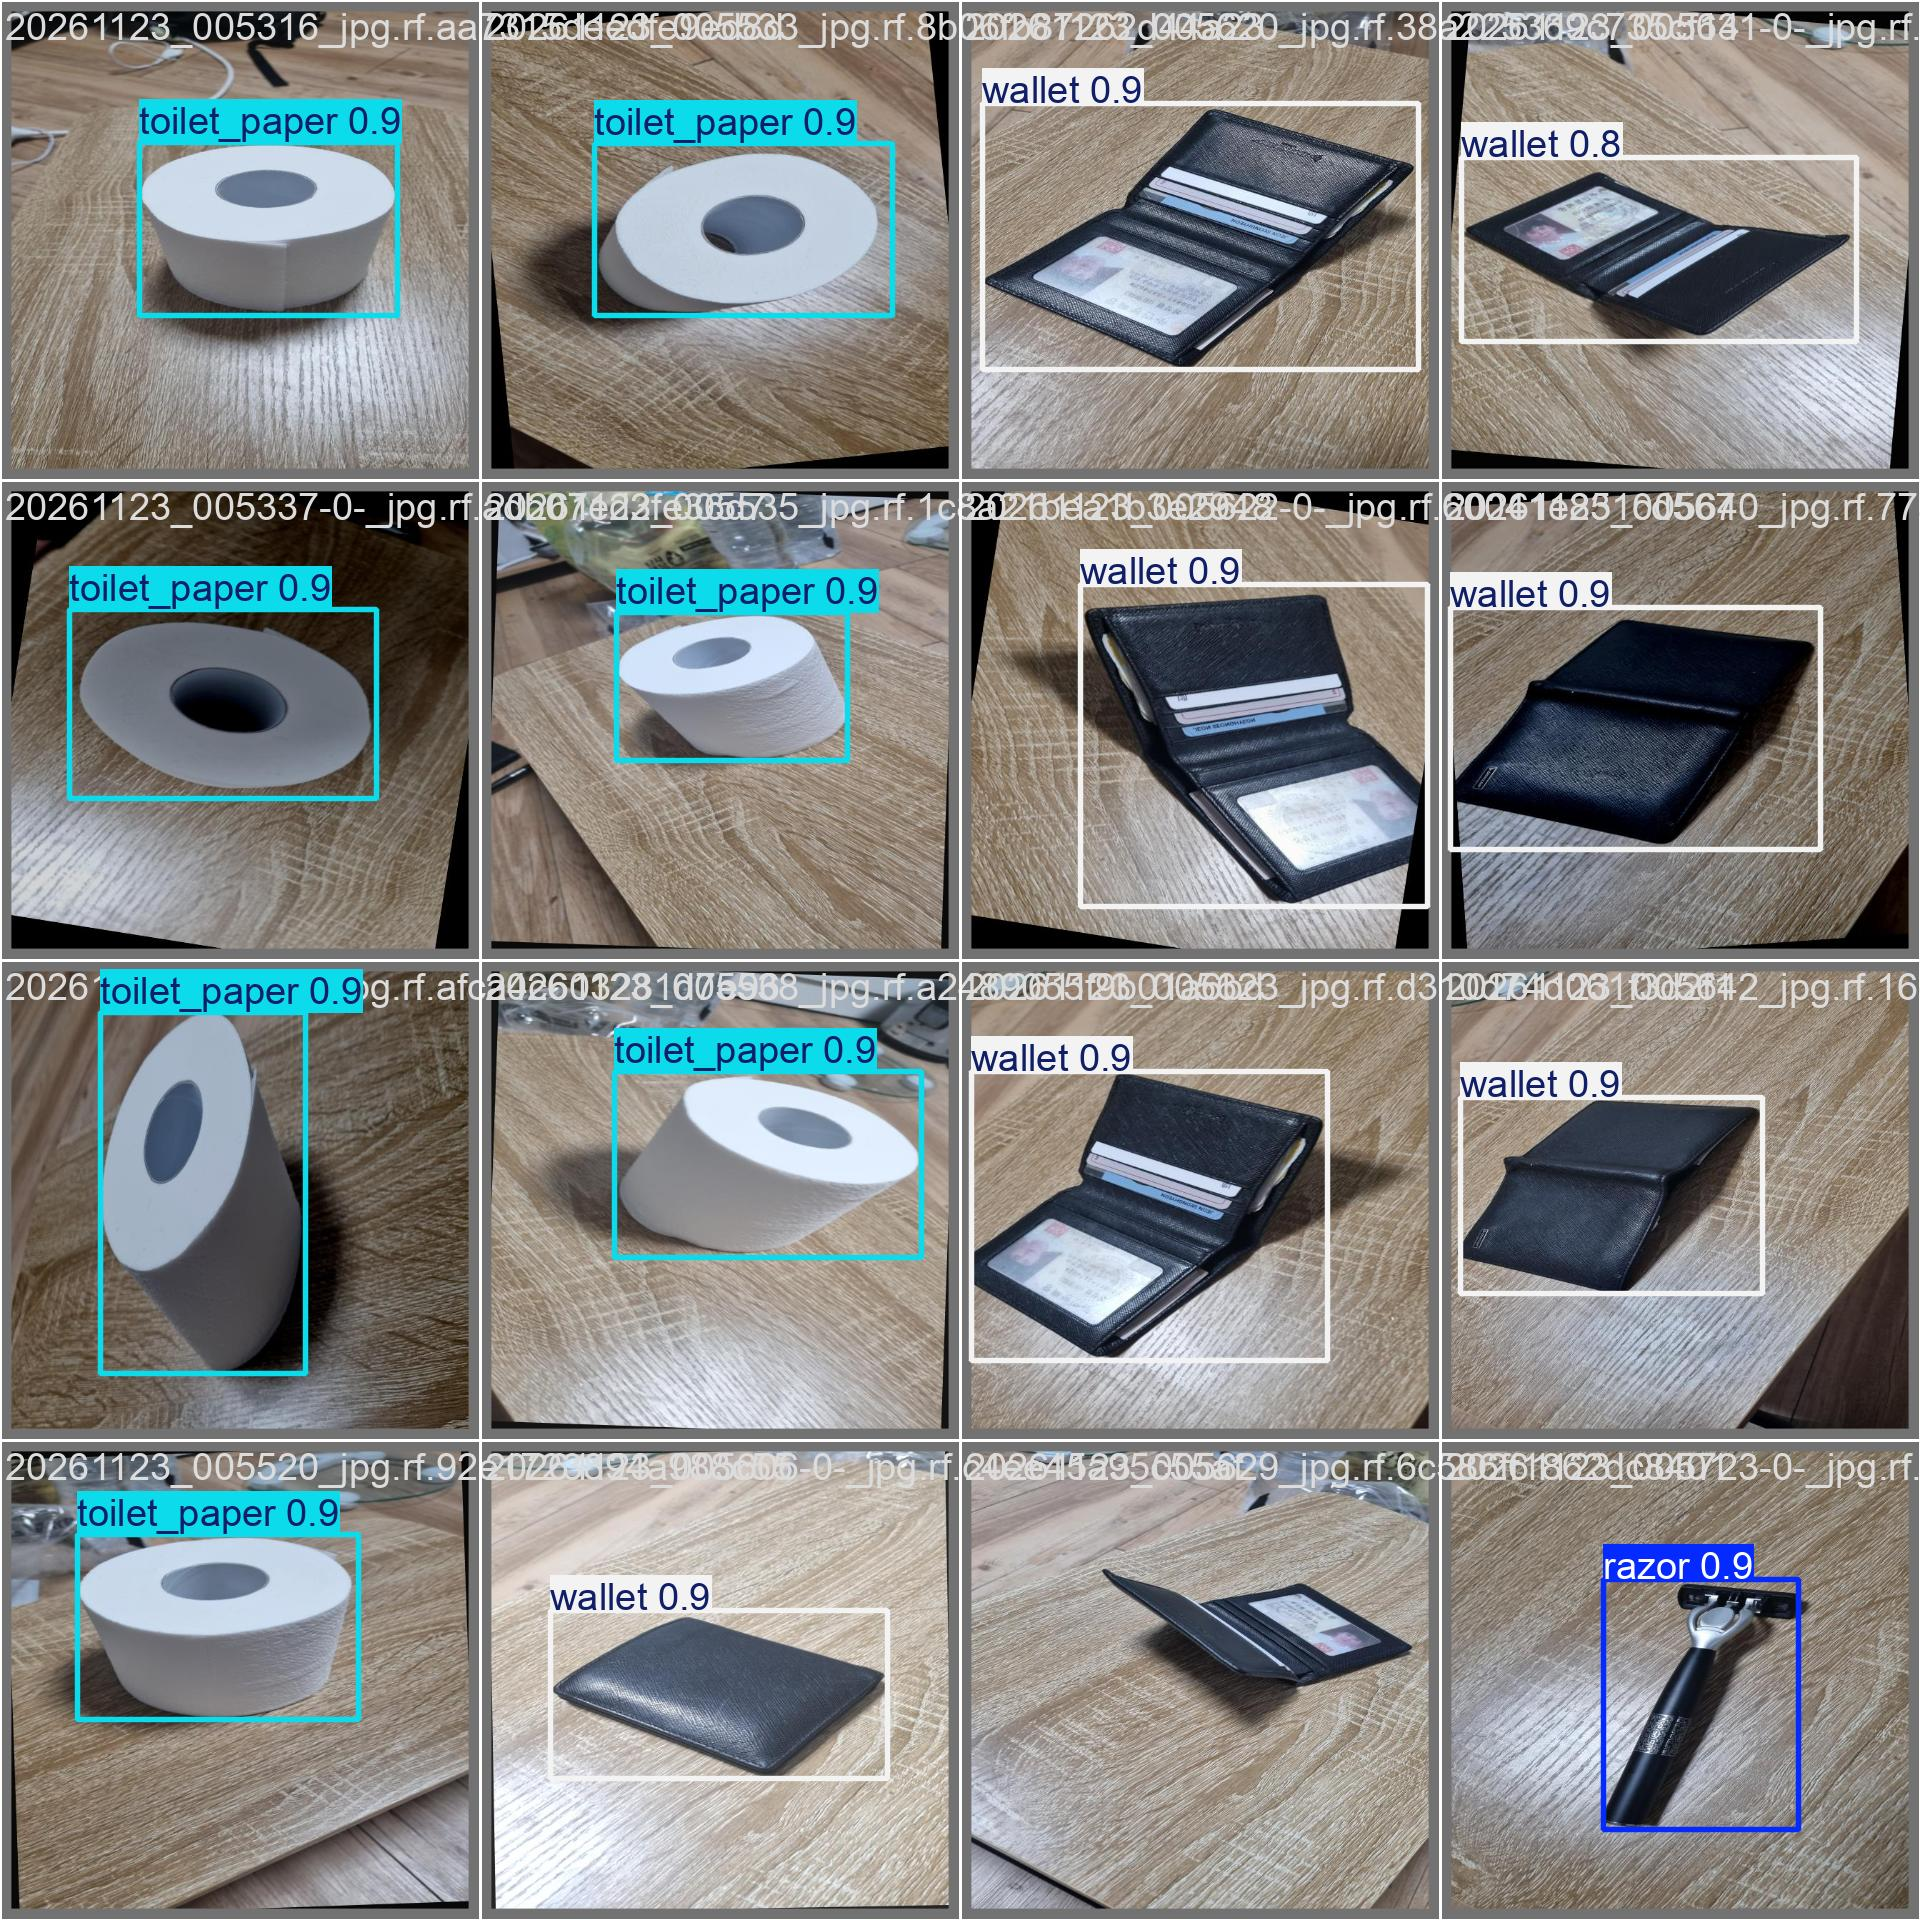

In [ ]:
from IPython.display import Image, display
RUN = str(model.trainer.save_dir)   # 버전에 따라 runs/detect/runs/hw 처럼 경로가 달라지므로 실제 저장 위치를 쓴다
print(RUN)
for f in ["results.png", "confusion_matrix.png", "PR_curve.png", "F1_curve.png", "val_batch0_pred.jpg"]:
    p = f"{RUN}/{f}"
    if os.path.exists(p):
        print(f); display(Image(filename=p, width=700))

In [ ]:
best = YOLO(f"{RUN}/weights/best.pt")
m = best.val(data=DATA_YAML, split="test" if os.path.exists(f"{root}/test") else "val")
print(f"Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")
for i, name in best.names.items():
    print(f"  {name:>12s}: mAP50-95 = {m.box.maps[i]:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1231.9±729.6 MB/s, size: 79.3 KB)
val: Scanning /content/machine-learning-1/test/labels... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 441.7it/s 0.0s
val: New cache created: /content/machine-learning-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.5it/s 0.2s
                   all         10         10      0.983          1      0.995      0.848
                 razor          2          2      0.982          1      0.995      0.995
          toilet_paper          4          4      0.981          1      0.995       0.92
                wallet          4          4      0.986          1      0.995      0.628
Speed: 0.4ms preprocess, 6.4ms inference, 0.0ms loss, 1.6ms postproc

## 4. 동영상 객체 감지 + 추적 (5초)
학습한 3개 부류가 나오는 영상(직접 촬영 추천)을 업로드한다. 슬라이드에서 말한 대로 기본 `track()`은 궤적을 따로 저장하지 않으므로, 아래 코드는 객체 ID별 중심점 궤적을 영상 위에 그리고 `trajectory.csv`로도 저장한다.

In [ ]:
from google.colab import files
up = files.upload()            # 원본 영상 선택
SRC = list(up.keys())[0]
START_SEC = 0                  # TODO: 영상에서 쓰고 싶은 구간의 시작 초

Saving Video Project.mp4 to Video Project.mp4


In [ ]:
import cv2, csv, numpy as np
from collections import defaultdict

cap = cv2.VideoCapture(SRC)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.set(cv2.CAP_PROP_POS_MSEC, START_SEC * 1000)
out = cv2.VideoWriter("track_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

history = defaultdict(list)    # track_id -> [(x, y), ...]
rows, f = [], 0
while f < int(fps * 5):        # 5초 분량
    ok, frame = cap.read()
    if not ok: break
    r = best.track(frame, persist=True, conf=0.4, tracker="bytetrack.yaml", verbose=False)[0]
    img = r.plot()
    if r.boxes.id is not None:
        xywh = r.boxes.xywh.cpu().numpy()
        ids  = r.boxes.id.int().cpu().tolist()
        clss = r.boxes.cls.int().cpu().tolist()
        for (x, y, w, h), tid, c in zip(xywh, ids, clss):
            history[tid].append((float(x), float(y)))
            history[tid] = history[tid][-60:]          # 최근 60프레임만 그림
            rows.append([f, round(f / fps, 3), tid, best.names[c], round(float(x), 1), round(float(y), 1)])
            pts = np.array(history[tid], np.int32).reshape(-1, 1, 2)
            cv2.polylines(img, [pts], False, (0, 255, 255), 2)
    out.write(img); f += 1
cap.release(); out.release()

with open("trajectory.csv", "w", newline="") as fp:
    csv.writer(fp).writerows([["frame", "time_s", "track_id", "class", "cx", "cy"]] + rows)
print(f"{f}프레임 처리, 추적된 객체 수 {len(history)}개")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 195ms
Prepared 1 package in 51ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

150프레임 처리, 추적된 객체 수 5개


In [ ]:
# mp4v는 GitHub/브라우저에서 재생이 안 될 수 있어 H.264로 변환한다
!ffmpeg -y -loglevel error -i track_raw.mp4 -vcodec libx264 -preset veryfast -pix_fmt yuv420p track_result.mp4
from IPython.display import HTML; from base64 import b64encode
HTML(f'<video width=640 controls><source src="data:video/mp4;base64,{b64encode(open("track_result.mp4","rb").read()).decode()}" type="video/mp4"></video>')

## 5. 결과물 정리 및 다운로드 (GitHub 업로드용)

In [ ]:
!mkdir -p submit/weights submit/results
!cp {RUN}/weights/best.pt submit/weights/
!cp {RUN}/results.png {RUN}/confusion_matrix.png {RUN}/PR_curve.png {RUN}/args.yaml submit/results/ 2>/dev/null
!cp track_result.mp4 trajectory.csv submit/
!cd submit && zip -qr ../submit.zip . && ls -R
files.download("submit.zip")

.:
results  track_result.mp4  trajectory.csv  weights

./results:
args.yaml  confusion_matrix.png  results.png

./weights:
best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>